In [5]:
import sys
from pathlib import Path
here = Path.cwd()
ROOT = next(p for p in [here, *here.parents] if (p / "src" / "model.py").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss, confusion_matrix
from src.data import ORDERS_PATH, TARGET
from src.model import FEATURES, time_split, make_boosting

orders = pd.read_csv(ORDERS_PATH, parse_dates=["order_date"])
train, test = time_split(orders)
model = make_boosting().fit(train[FEATURES], train[TARGET])
y, prob = test[TARGET].to_numpy(), model.predict_proba(test[FEATURES])[:, 1]

In [2]:
frac_late, mean_pred = calibration_curve(y, prob, n_bins=10, strategy="quantile")
print(pd.DataFrame({"model said": mean_pred.round(3), "actually late": frac_late.round(3)}))
print("Brier score:", round(brier_score_loss(y, prob), 4), "(0 = perfect; always saying 0.574 would score", round(brier_score_loss(y, np.full(len(y), y.mean())), 4), ")")

   model said  actually late
0       0.259          0.301
1       0.385          0.375
2       0.400          0.394
3       0.412          0.401
4       0.426          0.395
5       0.455          0.406
6       0.714          0.708
7       0.809          0.802
8       0.982          0.981
Brier score: 0.1749 (0 = perfect; always saying 0.574 would score 0.2445 )


best threshold: 0.05 | cost per order $ 2.922 | at 0.5: $ 4.638 | flag nothing: $ 8.617


,threshold,cost_per_order,share_flagged
0,0.05,2.922,0.974
1,0.10,2.922,0.974
2,0.15,2.922,0.974
3,0.20,2.922,0.974
4,0.25,2.922,0.974
5,0.30,2.932,0.972
6,0.35,3.032,0.938
7,0.40,3.561,0.748
8,0.45,4.435,0.457
9,0.50,4.638,0.390


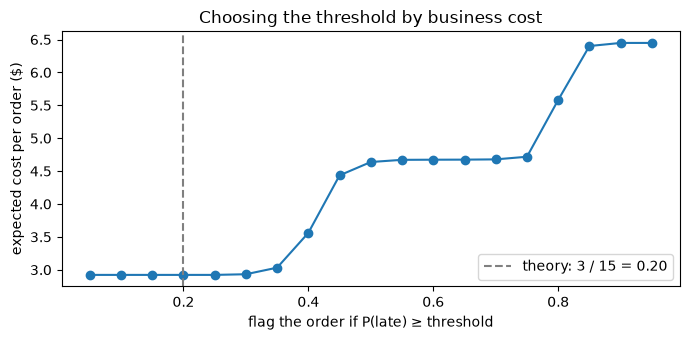

In [3]:
COST_FLAG, COST_MISSED_LATE = 3, 15

def cost_per_order(threshold):
    flag = prob >= threshold
    return (flag.sum() * COST_FLAG + ((~flag) & (y == 1)).sum() * COST_MISSED_LATE) / len(y)

thresholds = np.round(np.arange(0.05, 1.0, 0.05), 2)
costs = pd.DataFrame({"threshold": thresholds,
                      "cost_per_order": [round(cost_per_order(t), 3) for t in thresholds],
                      "share_flagged": [round((prob >= t).mean(), 3) for t in thresholds]})
best = costs.loc[costs["cost_per_order"].idxmin()]
print("best threshold:", best["threshold"], "| cost per order $", best["cost_per_order"],
      "| at 0.5: $", round(cost_per_order(0.5), 3), "| flag nothing: $", round(cost_per_order(1.01), 3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(costs["threshold"], costs["cost_per_order"], marker="o")
ax.axvline(0.2, linestyle="--", color="gray", label="theory: 3 / 15 = 0.20")
ax.set_xlabel("flag the order if P(late) ≥ threshold")
ax.set_ylabel("expected cost per order ($)")
ax.set_title("Choosing the threshold by business cost")
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / "docs" / "cost_curve.png", dpi=150)
costs

In [4]:
for t in [0.5, best["threshold"]]:
    tn, fp, fn, tp = confusion_matrix(y, prob >= t).ravel()
    print(f"threshold {t}: flagged {tp + fp:5}  | caught late {tp:5} | missed late {fn:5} | flagged but on time {fp:5}")

threshold 0.5: flagged  4902  | caught late  4318 | missed late  2909 | flagged but on time   584
threshold 0.05: flagged 12252  | caught late  7227 | missed late     0 | flagged but on time  5025
